# Step 4: The reply network

Who replies to whom, and did that change as the room got quieter? Step 3 found that explicit
reply share rose without an identified cause; one possible cause is a change in who talks to
whom:

- **Q1: does modularity rise?** Modularity measures how strongly a network splits into groups
  that reply mostly among themselves.
- **Q2: do effective partners fall?** Effective partners is the number of people a member would
  reply to if they spread their replies evenly: a measure of how widely they reply.

**In short:** the core of the network was fully connected in both periods. Among the 15 core
members who use the Reply button, all 210 directed pairs exchanged replies in both periods
(46,632 replies over 952 days late, against 71,528 over 730 early).

The structural measures (density, the share of all possible reply links that exist; and
effective partners) shrink toward no change as the
comparison is limited to members more active in both periods; their apparent falls come mostly
from members who stopped posting. What the network does show is preference: some pairs reply to each other more than
their activity predicts, and those preferences persisted.

Three things distort a naive comparison, and each is handled:

1. **Reply share rises over time**, so later messages produce more edges (an edge is a reply
   link from one member to another). Edges are counted per message.
2. **Fewer replies means fewer chances to see a rare pair.** Both periods are rarefied: randomly
   cut down to the same number of replies.
3. **Members who stopped posting have no edges afterwards.** Comparisons use members active in
   both periods, at several activity bars.

In [1]:
import re
import os
import warnings
import psycopg2
import pandas as pd

warnings.filterwarnings("ignore", message=".*only supports SQLAlchemy.*")

REPO_ROOT = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
SQL_PATH = os.path.join(REPO_ROOT, "sql", "04_network.sql")
TABLES_DIR = os.path.join(REPO_ROOT, "outputs", "tables")
# per-member hourly data stays private (outputs/private/ is not published)
PRIVATE_DIR = os.path.join(REPO_ROOT, "outputs", "private")
PRIVATE_TABLES = {"member_posts_dayhour", "reply_edges_dayhour"}
os.makedirs(TABLES_DIR, exist_ok=True)

def load_labeled_queries(path):
    with open(path, encoding="utf-8") as f:
        sql = f.read()
    parts = re.split(r"--\s*QUERY:\s*(\w+)", sql)
    return {name: body.strip().rstrip(";") for name, body in zip(parts[1::2], parts[2::2])}

queries = load_labeled_queries(SQL_PATH)
print(f"Loaded {len(queries)} labeled queries: {list(queries.keys())}")

Loaded 6 labeled queries: ['reply_edges', 'period_totals', 'mention_edges', 'member_period_activity', 'member_posts_dayhour', 'reply_edges_dayhour']


In [2]:
try:
    conn = psycopg2.connect(host="localhost", port=5432, dbname="postgres", user="postgres",
                            options="-c timezone=Europe/Bucharest")
except psycopg2.OperationalError:
    conn = None
    print("No database connection: using the saved tables in outputs/tables/.")
if conn is not None:
    for name, sql in queries.items():
        out_dir = PRIVATE_DIR if name in PRIVATE_TABLES else TABLES_DIR
        os.makedirs(out_dir, exist_ok=True)
        df = pd.read_sql(sql, conn)
        df.to_csv(os.path.join(out_dir, f"{name}.csv"), index=False)
        print(f"{name}: {len(df)} rows")
    conn.close()

reply_edges: 1669 rows


period_totals: 3 rows


mention_edges: 1659 rows


member_period_activity: 79 rows


member_posts_dayhour: 157789 rows


reply_edges_dayhour: 113764 rows


In [3]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid")
CHARTS_DIR = os.path.join(REPO_ROOT, "outputs", "charts")
os.makedirs(CHARTS_DIR, exist_ok=True)

edges    = pd.read_csv(os.path.join(TABLES_DIR, "reply_edges.csv"))
totals   = pd.read_csv(os.path.join(TABLES_DIR, "period_totals.csv"))
mentions = pd.read_csv(os.path.join(TABLES_DIR, "mention_edges.csv"))
activity = pd.read_csv(os.path.join(TABLES_DIR, "member_period_activity.csv"))

EARLY, LATE = "early", "late"
rng = np.random.default_rng(42)
E = edges[edges["period"] == EARLY]
L = edges[edges["period"] == LATE]
msgs = activity.pivot(index="pseudonym", columns="period", values="messages").fillna(0)

def build(df):
    """Directed weighted reply graph plus its undirected collapse. Community
    detection uses the undirected one: A->B and B->A are not separate
    relationships here."""
    G = nx.DiGraph()
    for s, t, w in df[["source", "target", "weight"]].itertuples(index=False):
        G.add_edge(s, t, weight=w)
    U = nx.Graph()
    for u, v, d in G.edges(data=True):
        prev = U.get_edge_data(u, v, {"weight": 0})["weight"]
        U.add_edge(u, v, weight=prev + d["weight"])
    return G, U

def effective_partners(G, min_replies=50):
    """exp(Shannon entropy) of a member's outgoing reply weights: the number
    of partners they would need to reply to evenly to show this spread."""
    out = {}
    for n in G.nodes():
        w = np.array([d["weight"] for _, _, d in G.out_edges(n, data=True)], dtype=float)
        if w.sum() < min_replies or len(w) == 0:
            continue
        p = w / w.sum()
        out[n] = float(np.exp(-(p * np.log(p)).sum()))
    return out

def metrics(df):
    G, U = build(df)
    comm = nx.community.louvain_communities(U, weight="weight", seed=1)
    eff = effective_partners(G)
    return {"nodes": G.number_of_nodes(), "edges": G.number_of_edges(),
            "density": nx.density(G),
            "modularity": nx.community.modularity(U, comm, weight="weight"),
            "communities": len(comm),
            "eff_partners": float(np.mean(list(eff.values()))) if eff else np.nan}

def rarefy(df, n, rng):
    """Subsample n individual reply events (not edges) without replacement."""
    idx = np.repeat(np.arange(len(df)), df["weight"].values)
    out = df.copy()
    out["weight"] = np.bincount(rng.choice(idx, size=n, replace=False), minlength=len(df))
    return out[out["weight"] > 0]

N_EARLY, N_LATE = int(E["weight"].sum()), int(L["weight"].sum())
print(totals[["period", "days", "messages_included_members", "reply_messages",
              "reply_share", "members_posting"]].round(3).to_string(index=False))
print()
for p, n in [(EARLY, N_EARLY), (LATE, N_LATE)]:
    m = totals.loc[totals["period"] == p, "messages_included_members"].iloc[0]
    print(f"{p:>6}: {n:>7,} reply events   {1000 * n / m:6.1f} edges per 1,000 messages")
print()
print(f"Reply-event ratio early:late = {N_EARLY / N_LATE:.3f}.")

period  days  messages_included_members  reply_messages  reply_share  members_posting
 early   730                     842577           89260        0.106               27
   mid   365                     273988           32945        0.120               26
  late   952                     492568           70727        0.143               26

 early:  85,582 reply events    101.6 edges per 1,000 messages
  late:  67,731 reply events    137.5 edges per 1,000 messages

Reply-event ratio early:late = 1.264.


## Who leaves the core?

The core here is every member with at least one strong reply link: 40 or more replies with one
other member in the period. Seven members drop out of it between the periods.

In [4]:
MIN_W_EARLY = 40
MIN_W_LATE = int(round(MIN_W_EARLY / (N_EARLY / N_LATE)))

def core(df, min_w):
    _, U = build(df)
    return {n for n in U.nodes()
            if any(d["weight"] >= min_w for _, _, d in U.edges(n, data=True))}

core_e = core(E, MIN_W_EARLY)
core_fixed = core(L, MIN_W_EARLY)
core_prop = core(L, MIN_W_LATE)

rows = []
for n in sorted(core_e - core_fixed):
    rows.append({"member": n,
                 "early_msgs": int(msgs.loc[n, EARLY]),
                 "late_msgs": int(msgs.loc[n, LATE]),
                 "reconnects_at_proportional": n in core_prop})
drop = pd.DataFrame(rows)
print(f"Fixed threshold {MIN_W_EARLY} both periods -> {len(drop)} members leave the core:")
print(drop.to_string(index=False))
print()
print(f"Proportional late threshold = {MIN_W_EARLY} / {N_EARLY / N_LATE:.3f} = {MIN_W_LATE}")
print(f"  core size: early {len(core_e)}, late(fixed {MIN_W_EARLY}) {len(core_fixed)}, "
      f"late(proportional {MIN_W_LATE}) {len(core_prop)}")
print()
gone = drop[drop["late_msgs"] == 0]["member"].tolist()
thresh = drop[drop["reconnects_at_proportional"]]["member"].tolist()
real = drop[(drop["late_msgs"] > 0) & (~drop["reconnects_at_proportional"])]["member"].tolist()
print(f"  {len(gone)} posted nothing in 2024-2026: {gone}")
print(f"  {len(thresh)} reconnect at the proportional threshold: {thresh}")
print(f"  {len(real)} genuine cases (still posting, but out of the core): {real}")
for n in real:
    print(f"       {n}: {int(msgs.loc[n, EARLY]):,} early msgs -> {int(msgs.loc[n, LATE]):,} late")

Fixed threshold 40 both periods -> 7 members leave the core:
 member  early_msgs  late_msgs  reconnects_at_proportional
user_20       17190          0                       False
user_21       13838          0                       False
user_23        7429        782                        True
user_25        8322         28                       False
user_26        7063          0                       False
user_27        5274        131                       False
user_29        1649        304                        True

Proportional late threshold = 40 / 1.264 = 32
  core size: early 27, late(fixed 40) 22, late(proportional 32) 24

  3 posted nothing in 2024-2026: ['user_20', 'user_21', 'user_26']
  2 reconnect at the proportional threshold: ['user_23', 'user_29']
  2 genuine cases (still posting, but out of the core): ['user_25', 'user_27']
       user_25: 8,322 early msgs -> 28 late
       user_27: 5,274 early msgs -> 131 late


## The structural comparison

Rarefied to equal numbers of replies, at several bars for "active in both periods". A real
structural change should survive the stricter bars; a change caused by people leaving should
fade.

The "all common members" row (26 members) includes two members with no late-period messages, who appear in the late
data only as the targets of replies to their old posts, so it understates late density.

In [5]:
DRAWS = 15

def compare(nodes, label):
    Ex = E[E["source"].isin(nodes) & E["target"].isin(nodes)]
    Lx = L[L["source"].isin(nodes) & L["target"].isin(nodes)]
    n = int(min(Ex["weight"].sum(), Lx["weight"].sum()))
    out = {"basis": label, "n_members": len(nodes), "rarefied_to": n}
    for lbl, df in [(EARLY, Ex), (LATE, Lx)]:
        res = [metrics(rarefy(df, n, rng)) for _ in range(DRAWS)]
        for k in ["density", "modularity", "eff_partners"]:
            out[f"{k}_{lbl}"] = float(np.mean([r[k] for r in res]))
    for k in ["density", "modularity", "eff_partners"]:
        out[f"{k}_change"] = out[f"{k}_{LATE}"] / out[f"{k}_{EARLY}"] - 1
    return out

common = sorted((set(E["source"]) | set(E["target"])) & (set(L["source"]) | set(L["target"])))
rows = [compare(common, "all common members")]
for thr in [1, 100, 500, 1000, 2000]:
    nodes = [n for n in common if msgs.loc[n, EARLY] >= thr and msgs.loc[n, LATE] >= thr]
    rows.append(compare(nodes, f"active >={thr} msgs both"))
sweep = pd.DataFrame(rows)
sweep.to_csv(os.path.join(TABLES_DIR, "network_activity_sweep.csv"), index=False)

print(f"{'basis':<26}{'n':>4}{'density':>22}{'eff partners':>24}")
for _, r in sweep.iterrows():
    print(f"{r.basis:<26}{r.n_members:>4}"
          f"   {r.density_early:.3f} -> {r.density_late:.3f} ({r.density_change:+.0%})"
          f"   {r.eff_partners_early:5.2f} -> {r.eff_partners_late:5.2f} ({r.eff_partners_change:+.0%})")
print()
print("Change at each bar:")
print(f"  density        {'  '.join(f'{v:+.0%}' for v in sweep['density_change'])}")
print(f"  eff partners   {'  '.join(f'{v:+.0%}' for v in sweep['eff_partners_change'])}")
print()
print()

basis                        n               density            eff partners
all common members          26   0.878 -> 0.643 (-27%)   12.89 -> 10.63 (-18%)
active >=1 msgs both        24   0.889 -> 0.754 (-15%)   12.26 -> 10.62 (-13%)
active >=100 msgs both      23   0.884 -> 0.810 (-8%)   11.92 -> 10.62 (-11%)
active >=500 msgs both      21   0.909 -> 0.902 (-1%)   11.72 -> 10.77 (-8%)
active >=1000 msgs both     20   0.918 -> 0.939 (+2%)   11.54 -> 10.83 (-6%)
active >=2000 msgs both     16   0.941 -> 0.996 (+6%)   10.64 -> 10.45 (-2%)

Change at each bar:
  density        -27%  -15%  -8%  -1%  +2%  +6%
  eff partners   -18%  -13%  -11%  -8%  -6%  -2%




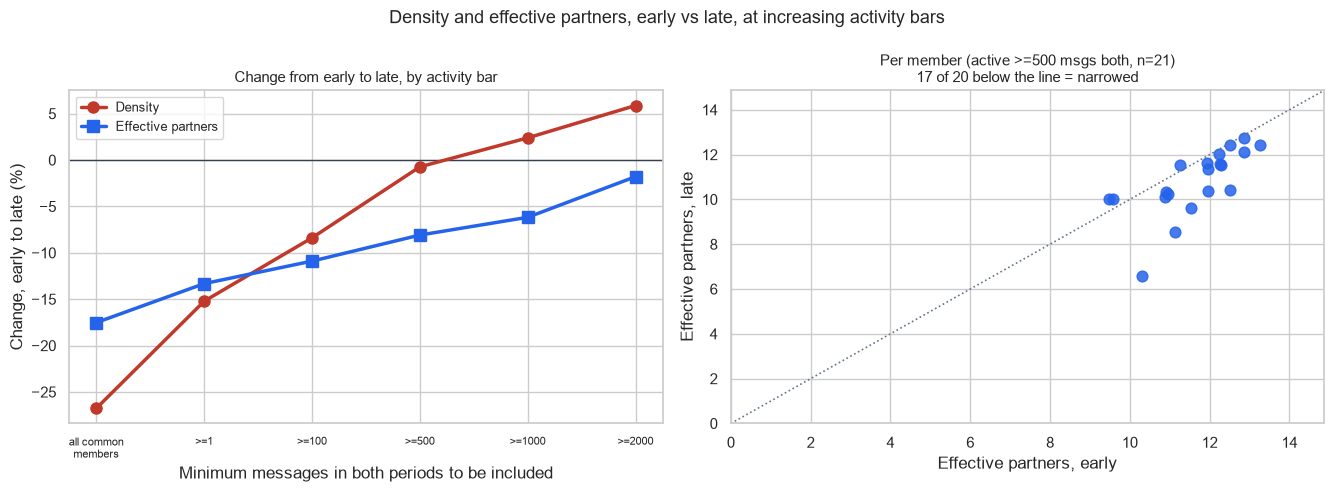

Headline basis: active >=500 msgs both (n=21 members, rarefied to 50,153 events)
  density        0.909 -> 0.902  (-0.7%)
  eff partners   11.72 -> 10.77  (-8.1%)
  narrowed: 17 of 20 members with a computable value in both
  1 of the 21 excluded from the scatter (under 50 outgoing replies in one period): ['user_14']
    user_14: 1 outgoing replies early, 105 late -- entropy on that few events is noise

Core connectivity (not rarefied):
  early: undirected 120/120 pairs   directed 226/240 (0.942)
   late: undirected 120/120 pairs   directed 239/240 (0.996)
  All 120 undirected pairs present in BOTH periods.

  Missing directed pairs:
    early: 14 missing directed pairs, sources = ['user_14']
     late:  1 missing directed pairs, sources = ['user_14']

  Excluding user_14 -- the 15 core members who USE the feature:
    early: 210/210 directed pairs    71,528 events over 730 days
     late: 210/210 directed pairs    46,632 events over 952 days


In [6]:
HEADLINE = "active >=500 msgs both"
h = sweep[sweep["basis"] == HEADLINE].iloc[0]
nodes_h = [n for n in common if msgs.loc[n, EARLY] >= 500 and msgs.loc[n, LATE] >= 500]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5))

x = np.arange(len(sweep))
ax1.axhline(0, color="#334155", linewidth=1)
ax1.plot(x, sweep["density_change"] * 100, marker="o", markersize=8, linewidth=2.5,
         color="#c0392b", label="Density")
ax1.plot(x, sweep["eff_partners_change"] * 100, marker="s", markersize=8, linewidth=2.5,
         color="#2563eb", label="Effective partners")
ax1.set_xticks(x)
ax1.set_xticklabels([b.replace("active >=", ">=").replace(" msgs both", "")
                     .replace("all common members", "all common\nmembers")
                     for b in sweep["basis"]], fontsize=8)
ax1.set_xlabel("Minimum messages in both periods to be included")
ax1.set_ylabel("Change, early to late (%)")
ax1.set_title("Change from early to late, by activity bar", fontsize=11)
ax1.legend(fontsize=9)

Ex = E[E["source"].isin(nodes_h) & E["target"].isin(nodes_h)]
Lx = L[L["source"].isin(nodes_h) & L["target"].isin(nodes_h)]
G_e, _ = build(Ex)
G_l, _ = build(Lx)
eff_e, eff_l = effective_partners(G_e), effective_partners(G_l)
pairs = sorted(set(eff_e) & set(eff_l))
ax2.scatter([eff_e[p] for p in pairs], [eff_l[p] for p in pairs], s=60,
            color="#2563eb", alpha=0.85)
lim = [0, max(max(eff_e.values()), max(eff_l.values())) * 1.12]
ax2.plot(lim, lim, color="#64748b", linestyle=":", linewidth=1.2)
ax2.set_xlim(lim); ax2.set_ylim(lim)
ax2.set_xlabel("Effective partners, early")
ax2.set_ylabel("Effective partners, late")
below = sum(1 for p in pairs if eff_l[p] < eff_e[p])
ax2.set_title(f"Per member ({HEADLINE}, n={len(nodes_h)})\n"
              f"{below} of {len(pairs)} below the line = narrowed", fontsize=11)

fig.suptitle("Density and effective partners, early vs late, at increasing activity bars",
             fontsize=13)
fig.tight_layout()
fig.savefig(os.path.join(CHARTS_DIR, "16_network_metrics.png"), dpi=150)
plt.show()

print(f"Headline basis: {HEADLINE} (n={len(nodes_h)} members, rarefied to {int(h.rarefied_to):,} events)")
print(f"  density        {h.density_early:.3f} -> {h.density_late:.3f}  ({h.density_change:+.1%})")
print(f"  eff partners   {h.eff_partners_early:.2f} -> {h.eff_partners_late:.2f}  ({h.eff_partners_change:+.1%})")
print(f"  narrowed: {below} of {len(pairs)} members with a computable value in both")
excluded = sorted(set(nodes_h) - set(pairs))
if excluded:
    print(f"  {len(excluded)} of the {len(nodes_h)} excluded from the scatter "
          f"(under 50 outgoing replies in one period): {excluded}")
    for n in excluded:
        oe = int(Ex[Ex["source"] == n]["weight"].sum())
        ol = int(Lx[Lx["source"] == n]["weight"].sum())
        print(f"    {n}: {oe} outgoing replies early, {ol} late -- entropy on that "
              f"few events is noise")

print()
print("Core connectivity (not rarefied):")
core_nodes = [n for n in common if msgs.loc[n, EARLY] >= 2000 and msgs.loc[n, LATE] >= 2000]
k = len(core_nodes)
poss_dir, poss_und = k * (k - 1), k * (k - 1) // 2
for lbl, src in [(EARLY, E), (LATE, L)]:
    d = src[src["source"].isin(core_nodes) & src["target"].isin(core_nodes)]
    Gd, _ = build(d)
    und = len({tuple(sorted((u, v))) for u, v in Gd.edges()})
    print(f"  {lbl:>5}: undirected {und}/{poss_und} pairs   "
          f"directed {Gd.number_of_edges()}/{poss_dir} "
          f"({Gd.number_of_edges() / poss_dir:.3f})")
import itertools
print(f"  All {poss_und} undirected pairs present in BOTH periods.")
print()
print("  Missing directed pairs:")
for lbl, src in [(EARLY, E), (LATE, L)]:
    d = src[src["source"].isin(core_nodes) & src["target"].isin(core_nodes)]
    have = set(zip(d["source"], d["target"]))
    miss = [(a, b) for a, b in itertools.permutations(core_nodes, 2) if (a, b) not in have]
    print(f"    {lbl:>5}: {len(miss):>2} missing directed pairs, "
          f"sources = {sorted({a for a, _ in miss})}")
print()
core15 = [n for n in core_nodes if n != "user_14"]
poss15 = len(core15) * (len(core15) - 1)
print(f"  Excluding user_14 -- the {len(core15)} core members who USE the feature:")
for lbl, src in [(EARLY, E), (LATE, L)]:
    d = src[src["source"].isin(core15) & src["target"].isin(core15)]
    days = int(totals.loc[totals["period"] == lbl, "days"].iloc[0])
    print(f"    {lbl:>5}: {len(set(zip(d['source'], d['target']))):>3}/{poss15} directed pairs   "
          f"{int(d['weight'].sum()):>7,} events over {days} days")

## The two graphs

Both use the same layout, so differences are structure rather than layout.

The late period has 21% fewer replies, so the edge thresholds are proportional: at least 40
replies early and 32 late. Pair counts are undirected (A↔B combined), so they are roughly double
the directed counts in `reply_edges.csv`.

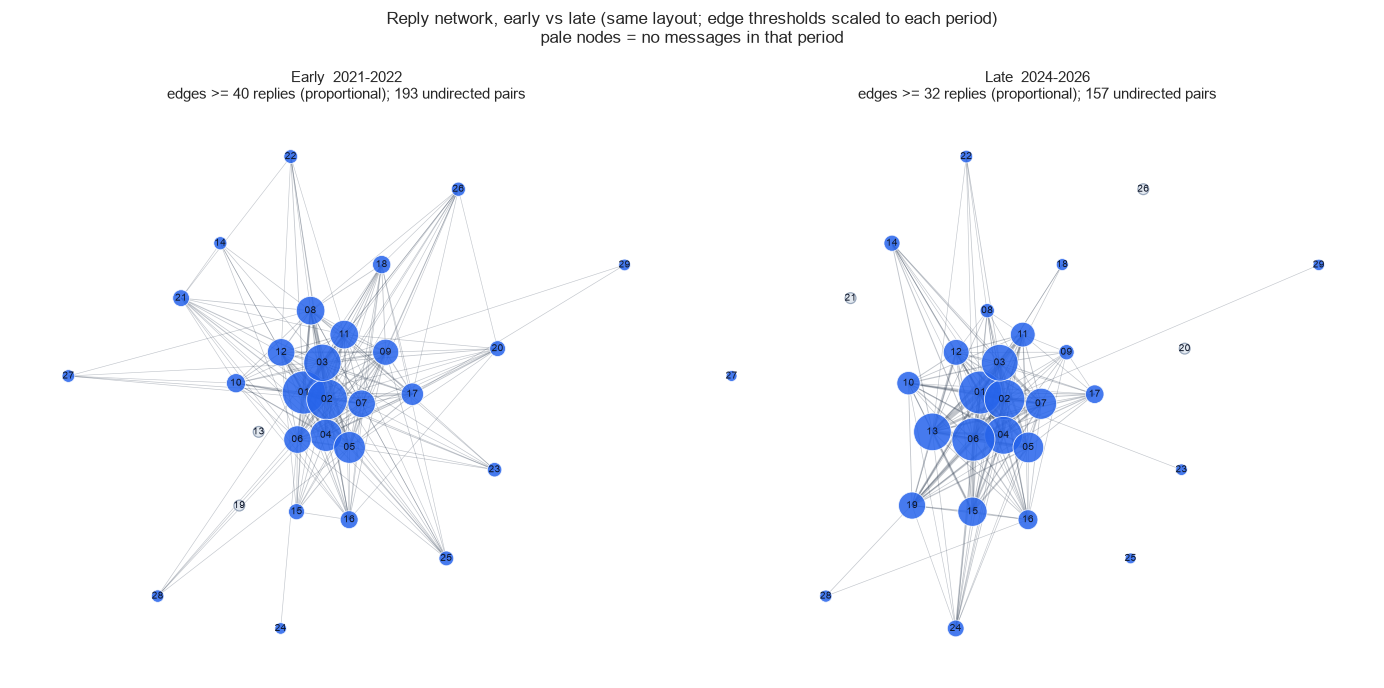

In [7]:
UNION_NODES = sorted(set(E["source"]) | set(E["target"]) | set(L["source"]) | set(L["target"]))
UNION = nx.Graph()
for df in (E, L):
    for s, t, w in df[["source", "target", "weight"]].itertuples(index=False):
        prev = UNION.get_edge_data(s, t, {"weight": 0})["weight"]
        UNION.add_edge(s, t, weight=prev + w)
pos = nx.spring_layout(UNION, weight="weight", seed=7, k=0.55, iterations=300)

_, U_e = build(E)
_, U_l = build(L)
absent = {EARLY: {n for n in UNION_NODES if msgs.reindex([n]).fillna(0)[EARLY].iloc[0] == 0},
          LATE:  {n for n in UNION_NODES if msgs.reindex([n]).fillna(0)[LATE].iloc[0] == 0}}

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, (per, U, thr, title) in zip(axes, [(EARLY, U_e, MIN_W_EARLY, "Early  2021-2022"),
                                          (LATE, U_l, MIN_W_LATE, "Late  2024-2026")]):
    sub = nx.Graph()
    sub.add_nodes_from(UNION.nodes())
    for u, v, d in U.edges(data=True):
        if d["weight"] >= thr:
            sub.add_edge(u, v, weight=d["weight"])
    wdeg = {n: sum(d["weight"] for _, _, d in U.edges(n, data=True)) for n in UNION.nodes()}
    mx = max(wdeg.values()) or 1
    ews = [sub[u][v]["weight"] for u, v in sub.edges()]
    emx = max(ews) if ews else 1
    nx.draw_networkx_edges(sub, pos, ax=ax, width=[0.4 + 2.6 * w / emx for w in ews],
                           alpha=0.30, edge_color="#334155")
    live = [n for n in sub.nodes() if n not in absent[per]]
    dead = [n for n in sub.nodes() if n in absent[per]]
    nx.draw_networkx_nodes(sub, pos, ax=ax, nodelist=live,
                           node_size=[60 + 900 * wdeg[n] / mx for n in live],
                           node_color="#2563eb", alpha=0.85, linewidths=0.6,
                           edgecolors="white")
    nx.draw_networkx_nodes(sub, pos, ax=ax, nodelist=dead,
                           node_size=[60 + 900 * wdeg[n] / mx for n in dead],
                           node_color="#e2e8f0", alpha=0.95, linewidths=0.9,
                           edgecolors="#94a3b8")
    nx.draw_networkx_labels(sub, pos, ax=ax,
                            labels={n: n.replace("user_", "") for n in sub.nodes()},
                            font_size=7, font_color="#0f172a")
    ax.set_title(f"{title}\nedges >= {thr} replies (proportional); "
                 f"{sub.number_of_edges()} undirected pairs", fontsize=11)
    ax.axis("off")

fig.suptitle("Reply network, early vs late (same layout; edge thresholds scaled to each period)\n"
             "pale nodes = no messages in that period", fontsize=12.5)
fig.tight_layout()
fig.savefig(os.path.join(CHARTS_DIR, "17_network_graphs.png"), dpi=150)
plt.show()

## Robustness: the mention graph

Mentions (@user) are recorded separately from replies. Same activity-filtered members.

In [8]:
rows = []
for gname, src in [("replies", edges), ("mentions", mentions)]:
    a = src[(src["period"] == EARLY) & src["source"].isin(nodes_h) & src["target"].isin(nodes_h)]
    b = src[(src["period"] == LATE) & src["source"].isin(nodes_h) & src["target"].isin(nodes_h)]
    n = int(min(a["weight"].sum(), b["weight"].sum()))
    for lbl, df in [(EARLY, a), (LATE, b)]:
        res = [metrics(rarefy(df, n, rng)) for _ in range(DRAWS)]
        rows.append({"graph": gname, "period": lbl, "rarefied_to": n,
                     **{k: float(np.mean([r[k] for r in res]))
                        for k in ["density", "modularity", "eff_partners"]}})
mcmp = pd.DataFrame(rows)
print(mcmp.round(3).to_string(index=False))
print()
for g in ["replies", "mentions"]:
    a = mcmp[(mcmp["graph"] == g) & (mcmp["period"] == EARLY)].iloc[0]
    b = mcmp[(mcmp["graph"] == g) & (mcmp["period"] == LATE)].iloc[0]
    print(f"{g:>9}: density {a.density:.3f} -> {b.density:.3f} ({b.density/a.density-1:+.0%})   "
          f"eff partners {a.eff_partners:.2f} -> {b.eff_partners:.2f} "
          f"({b.eff_partners/a.eff_partners-1:+.0%})")

   graph period  rarefied_to  density  modularity  eff_partners
 replies  early        50153    0.908       0.026        11.711
 replies   late        50153    0.902       0.034        10.771
mentions  early        35944    0.905       0.045        11.004
mentions   late        35944    0.886       0.041        10.830

  replies: density 0.908 -> 0.902 (-1%)   eff partners 11.71 -> 10.77 (-8%)
 mentions: density 0.905 -> 0.886 (-2%)   eff partners 11.00 -> 10.83 (-2%)


## Lift: replies relative to what activity predicts

Density, modularity and effective partners all measure how much people reply. On a fully
connected network that mostly reflects how much each person posts. Lift compares each pair's
replies with what their activity alone predicts:

`expected(i→j)` = the replies i→j would get if every member kept their real totals sent and
received but chose whom to reply to at random. It's calculated with iterative proportional
fitting (a standard method that adjusts the expected values until every member's totals match),
with self-replies excluded.
`lift(i→j) = observed / expected`

Lift 1.0 means as expected; above 1, more than expected; below 1, less. Lift is analysed on a
log scale, so that 2× and 0.5× are the same distance from 1.

1. **Is there preference at all?** The spread of log-lift is compared with networks simulated
   from the expected values (a null model: what the network would look like with no preferences).
2. **Did it persist?** Each pair's early lift is correlated with its late lift.

In [9]:
def lift_matrix(df, nodes):
    """Observed, expected and lift matrices for one period."""
    ix = {n: i for i, n in enumerate(nodes)}
    M = np.zeros((len(nodes), len(nodes)))
    sub = df[df["source"].isin(nodes) & df["target"].isin(nodes)]
    for s, t, w in sub[["source", "target", "weight"]].itertuples(index=False):
        M[ix[s], ix[t]] = w
    np.fill_diagonal(M, 0)
    total = M.sum()
    exp = np.ones_like(M)
    np.fill_diagonal(exp, 0)
    sent, recv = M.sum(axis=1), M.sum(axis=0)
    for _ in range(1000):
        exp *= (sent / np.where(exp.sum(axis=1) > 0, exp.sum(axis=1), 1))[:, None]
        exp *= (recv / np.where(exp.sum(axis=0) > 0, exp.sum(axis=0), 1))[None, :]
    assert np.allclose(exp.sum(axis=1), sent, rtol=1e-6), "IPF did not converge"
    with np.errstate(divide="ignore", invalid="ignore"):
        lift = np.where(exp > 0, M / exp, np.nan)
    return M, exp, lift, total

def null_spread(exp, total, draws=200):
    """sd of log-lift when replies are allocated by volume alone."""
    p = (exp / exp.sum()).ravel()
    out = []
    for _ in range(draws):
        sim = rng.multinomial(int(total), p).reshape(exp.shape).astype(float)
        with np.errstate(divide="ignore", invalid="ignore"):
            L = np.where(exp > 0, sim / exp, np.nan)
        v = np.log(L[np.isfinite(L) & (L > 0)])
        out.append(v.std())
    return np.mean(out), np.std(out)

NODES = nodes_h
Me, Ee, Le, Te = lift_matrix(E, NODES)
Ml, El, Ll, Tl = lift_matrix(L, NODES)

pd.DataFrame([{"period": lbl, "source": NODES[i], "target": NODES[j], "replies": int(Mx[i, j]),
               "expected": float(Ex[i, j]), "lift": float(Lx[i, j]) if Mx[i, j] > 0 else 0.0}
              for lbl, Mx, Ex, Lx in [(EARLY, Me, Ee, Le), (LATE, Ml, El, Ll)]
              for i in range(len(NODES)) for j in range(len(NODES)) if i != j]
             ).to_csv(os.path.join(TABLES_DIR, "pair_lift_directed.csv"), index=False)

print(f"{len(NODES)} members, {len(NODES) * (len(NODES) - 1)} ordered pairs")
print()
print("1. Spread of log(lift), observed vs volume-only null")
for lbl, exp, lift, tot in [(EARLY, Ee, Le, Te), (LATE, El, Ll, Tl)]:
    obs = np.log(lift[np.isfinite(lift) & (lift > 0)]).std()
    mu, sd = null_spread(exp, tot)
    print(f"   {lbl:>6}: {int(tot):>7,} events   observed {obs:.3f}   "
          f"null {mu:.3f} (+/-{sd:.3f})   -> {obs / mu:.1f}x chance")
print()
print("2. Persistence: corr(log lift early, log lift late), by minimum reply count")
from scipy.stats import spearmanr
for floor in [0, 20, 50]:
    m = (Me >= floor) & (Ml >= floor) & np.isfinite(Le) & np.isfinite(Ll) & (Le > 0) & (Ll > 0)
    r = np.corrcoef(np.log(Le[m]), np.log(Ll[m]))[0, 1]
    rho = spearmanr(Le[m], Ll[m]).statistic
    print(f"   >={floor:>2} replies in both: {m.sum():>3} cells   "
          f"Pearson(log) {r:+.3f}   Spearman {rho:+.3f}")

21 members, 420 ordered pairs

1. Spread of log(lift), observed vs volume-only null
    early:  77,949 events   observed 0.755   null 0.279 (+/-0.046)   -> 2.7x chance
     late:  50,153 events   observed 0.787   null 0.333 (+/-0.022)   -> 2.4x chance

2. Persistence: corr(log lift early, log lift late), by minimum reply count
   >= 0 replies in both: 357 cells   Pearson(log) +0.579   Spearman +0.635
   >=20 replies in both: 191 cells   Pearson(log) +0.731   Spearman +0.721
   >=50 replies in both: 138 cells   Pearson(log) +0.735   Spearman +0.741


In [10]:
rows = []
for i in range(len(NODES)):
    for j in range(i + 1, len(NODES)):
        counts = [Me[i, j], Me[j, i], Ml[i, j], Ml[j, i]]
        if min(counts) < 20:
            continue
        rows.append({"member_a": NODES[i], "member_b": NODES[j],
                     "replies_total": int(sum(counts)),
                     "lift_early": float(np.mean([Le[i, j], Le[j, i]])),
                     "lift_late": float(np.mean([Ll[i, j], Ll[j, i]])),
                     "lift_mean": float(np.mean([Le[i, j], Le[j, i], Ll[i, j], Ll[j, i]]))})
pair_lift = pd.DataFrame(rows).sort_values("lift_mean", ascending=False)
pair_lift.to_csv(os.path.join(TABLES_DIR, "pair_lift.csv"), index=False)

print(f"{len(pair_lift)} mutual pairs with >=20 replies each way in both periods")
print(f"lift ranges {pair_lift['lift_mean'].min():.2f}x to {pair_lift['lift_mean'].max():.2f}x")
print()
print("strongest mutual preferences:")
print(pair_lift.head(6).round(2).to_string(index=False))
print()
print("weakest (talk far less than their volumes predict):")
print(pair_lift.tail(3).round(2).to_string(index=False))

raw = pd.DataFrame([(NODES[i], NODES[j], int(Me[i, j] + Me[j, i]), int(Ml[i, j] + Ml[j, i]))
                    for i in range(len(NODES)) for j in range(i + 1, len(NODES))],
                   columns=["member_a", "member_b", "replies_early", "replies_late"])
raw = raw.sort_values("replies_early", ascending=False)
top = raw.iloc[0]
top_lift = pair_lift[(pair_lift["member_a"] == top["member_a"]) & (pair_lift["member_b"] == top["member_b"])].iloc[0]
print()
print("busiest pairs by RAW reply count (early, both directions):")
print(raw.head(5).to_string(index=False))
print(f"the busiest, {top['member_a']} & {top['member_b']}, has lift {top_lift['lift_early']:.2f}x early and "
      f"{top_lift['lift_late']:.2f}x late.")

87 mutual pairs with >=20 replies each way in both periods
lift ranges 0.33x to 2.83x

strongest mutual preferences:
member_a member_b  replies_total  lift_early  lift_late  lift_mean
 user_03  user_22            343        1.98       3.67       2.83
 user_15  user_16            323        3.76       1.60       2.68
 user_09  user_12           1352        3.00       2.03       2.51
 user_06  user_28            147        2.79       2.01       2.40
 user_09  user_16            253        1.72       2.79       2.26
 user_04  user_16           1003        2.33       2.08       2.20

weakest (talk far less than their volumes predict):
member_a member_b  replies_total  lift_early  lift_late  lift_mean
 user_03  user_15            290        0.43       0.35       0.39
 user_05  user_12            374        0.33       0.42       0.38
 user_06  user_17            180        0.30       0.37       0.33

busiest pairs by RAW reply count (early, both directions):
member_a member_b  replies_early 

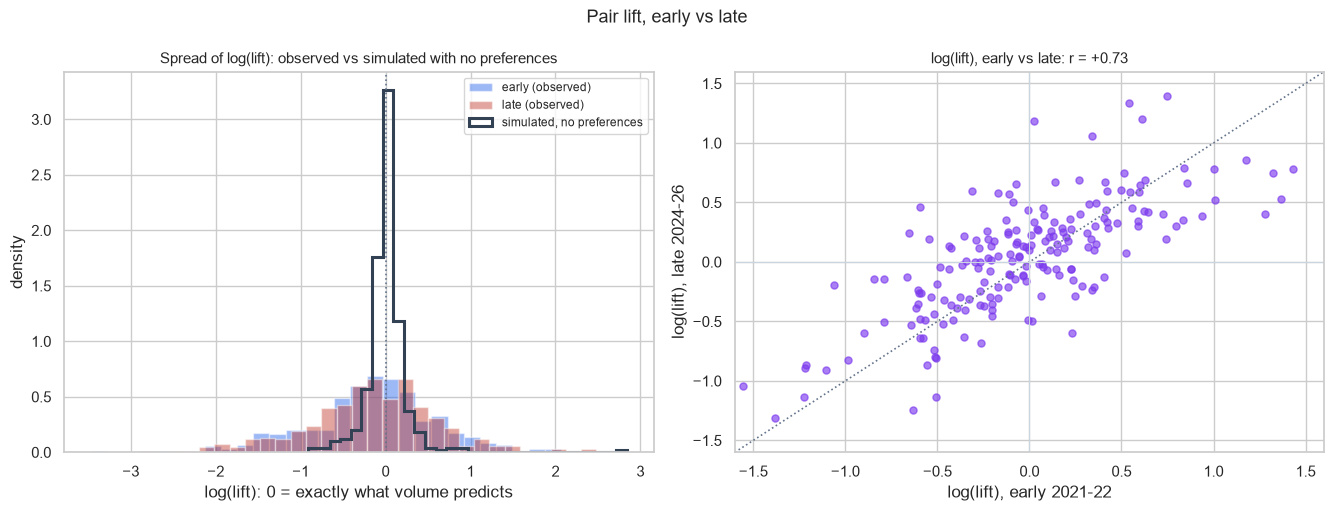

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.2))

for lbl, exp, lift, colour in [(EARLY, Ee, Le, "#2563eb"), (LATE, El, Ll, "#c0392b")]:
    obs = np.log(lift[np.isfinite(lift) & (lift > 0)])
    ax1.hist(obs, bins=30, alpha=0.45, color=colour, label=f"{lbl} (observed)", density=True)
p = (Ee / Ee.sum()).ravel()
sim = rng.multinomial(int(Te), p).reshape(Ee.shape).astype(float)
with np.errstate(divide="ignore", invalid="ignore"):
    Lnull = np.where(Ee > 0, sim / Ee, np.nan)
ax1.hist(np.log(Lnull[np.isfinite(Lnull) & (Lnull > 0)]), bins=30, histtype="step",
         linewidth=2.2, color="#334155", label="simulated, no preferences", density=True)
ax1.axvline(0, color="#64748b", linestyle=":", linewidth=1.2)
ax1.set_xlabel("log(lift): 0 = exactly what volume predicts")
ax1.set_ylabel("density")
ax1.set_title("Spread of log(lift): observed vs simulated with no preferences", fontsize=11)
ax1.legend(fontsize=8.5)

m = (Me >= 20) & (Ml >= 20) & np.isfinite(Le) & np.isfinite(Ll) & (Le > 0) & (Ll > 0)
ax2.scatter(np.log(Le[m]), np.log(Ll[m]), s=26, alpha=0.65, color="#7c3aed")
lo, hi = -1.6, 1.6
ax2.plot([lo, hi], [lo, hi], color="#64748b", linestyle=":", linewidth=1.2)
ax2.axhline(0, color="#cbd5e1", linewidth=0.8)
ax2.axvline(0, color="#cbd5e1", linewidth=0.8)
r = np.corrcoef(np.log(Le[m]), np.log(Ll[m]))[0, 1]
ax2.set_xlim(lo, hi); ax2.set_ylim(lo, hi)
ax2.set_xlabel("log(lift), early 2021-22")
ax2.set_ylabel("log(lift), late 2024-26")
ax2.set_title(f"log(lift), early vs late: r = {r:+.2f}", fontsize=11)

fig.suptitle("Pair lift, early vs late",
             fontsize=13)
fig.tight_layout()
fig.savefig(os.path.join(CHARTS_DIR, "20_pair_lift.png"), dpi=150)
plt.show()

### The interaction map

Rows are repliers, columns are who they replied to, averaged across both periods. Red = more
than their activity predicts, blue = less. Members are ordered by hierarchical clustering, which
places members with similar reply patterns next to each other.

Pairs with fewer than 20 replies in either period are greyed out, since a pair with two replies
can show a lift of 5 by chance.

A heatmap can't show that groups are absent; that's tested against simulated networks below.

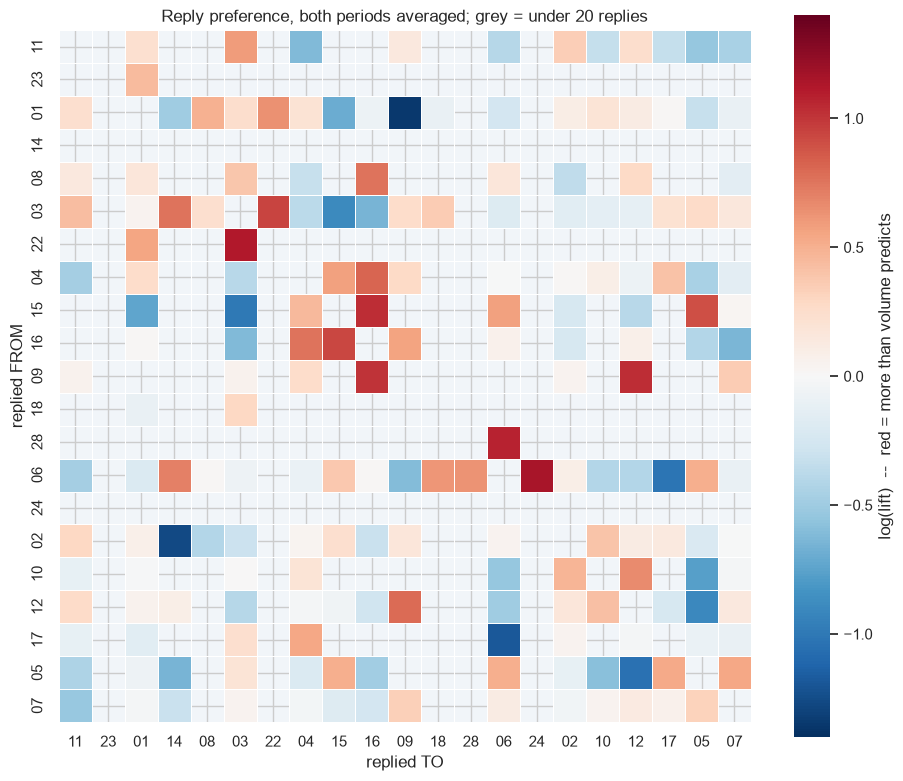

191 of 420 directed cells clear the 20-reply floor (45%); all 21 members keep at least one.
Colour scale is +/-1.4 -- set from the data, so nothing is clipped.



In [12]:
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    Lmean = np.nanmean(np.dstack([Le, Ll]), axis=2)
Lmean = np.where(np.isfinite(Lmean), Lmean, 1.0)
np.fill_diagonal(Lmean, 1.0)
Lmean = np.clip(Lmean, 0.05, None)

sym = (np.log(Lmean) + np.log(Lmean).T) / 2
dist = np.max(sym) - sym
np.fill_diagonal(dist, 0)
dist = (dist + dist.T) / 2
order = leaves_list(linkage(squareform(dist, checks=False), method="average"))
labels = [NODES[i].replace("user_", "") for i in order]

FLOOR = 20
mask = ~((Me >= FLOOR) & (Ml >= FLOOR))
np.fill_diagonal(mask, True)

logL = np.log(Lmean)
shown = logL[~mask]
lim = float(np.ceil(np.abs(shown).max() * 10) / 10)

fig, ax = plt.subplots(figsize=(9.5, 8))
sns.heatmap(logL[np.ix_(order, order)], cmap="RdBu_r", center=0,
            vmin=-lim, vmax=lim, ax=ax, square=True,
            mask=mask[np.ix_(order, order)],
            xticklabels=labels, yticklabels=labels,
            cbar_kws={"label": "log(lift)  --  red = more than volume predicts"},
            linewidths=0.4, linecolor="white")
ax.set_facecolor("#f1f5f9")
ax.set_xlabel("replied TO")
ax.set_ylabel("replied FROM")
ax.set_title(f"Reply preference, both periods averaged; grey = under {FLOOR} replies",
             fontsize=12)
fig.tight_layout()
fig.savefig(os.path.join(CHARTS_DIR, "21_lift_heatmap.png"), dpi=150)
plt.show()

print(f"{(~mask).sum()} of {len(NODES) * (len(NODES) - 1)} directed cells clear the "
      f"{FLOOR}-reply floor ({(~mask).sum() / (len(NODES) * (len(NODES) - 1)):.0%}); "
      f"all {len(NODES)} members keep at least one.")
print(f"Colour scale is +/-{lim} -- set from the data, so nothing is clipped.")
print()

### Group structure: modularity against simulated networks

Modularity on a fully connected network is small, so it's compared with 200 networks simulated
from the expected values (real totals, no preferences).

The groups are found by a greedy optimiser, an algorithm that searches for the grouping with the
highest modularity. The change in modularity is checked by resampling: rebuilding each period's
network 200 times at random from its own replies, to see how much the value moves by chance.

In [13]:
import itertools

def as_graph(M):
    S = M + M.T
    U = nx.Graph()
    for i, j in itertools.combinations(range(len(NODES)), 2):
        if S[i, j] > 0:
            U.add_edge(NODES[i], NODES[j], weight=S[i, j])
    return U

def best_q(M):
    U = as_graph(M)
    comms = nx.community.greedy_modularity_communities(U, weight="weight")
    return nx.community.modularity(U, comms, weight="weight"), comms

parts, qs = {}, {}
print("modularity, observed vs 200 volume-only null networks (greedy optimiser):")
for lbl, Mx, Ex in [(EARLY, Me, Ee), (LATE, Ml, El)]:
    q_obs, comms = best_q(Mx)
    qs[lbl] = q_obs
    parts[lbl] = {n: k for k, c in enumerate(comms) for n in c}
    p = (Ex / Ex.sum()).ravel()
    q_null = [best_q(rng.multinomial(int(Mx.sum()), p).reshape(Mx.shape).astype(float))[0]
              for _ in range(200)]
    print(f"  {lbl:>5}: observed Q {q_obs:.4f} in {len(comms)} groups   "
          f"null mean {np.mean(q_null):.5f}, max {np.max(q_null):.5f}")
    for c in sorted(comms, key=len, reverse=True):
        print("         " + ", ".join(sorted(x.replace("user_", "") for x in c)))

pairs = list(itertools.combinations(NODES, 2))
def agreement(a, b):
    return np.mean([(a[x] == a[y]) == (b[x] == b[y]) for x, y in pairs])
agree = agreement(parts[EARLY], parts[LATE])
late_labels = [parts[LATE][n] for n in NODES]
null_agree = [agreement(parts[EARLY], dict(zip(NODES, rng.permutation(late_labels))))
              for _ in range(2000)]
print()
print(f"same-group agreement, early vs late: {agree:.2f}   "
      f"chance {np.mean(null_agree):.2f} (95th pct {np.percentile(null_agree, 95):.2f})")

from collections import Counter
early_groups = {}
for n, k in parts[EARLY].items():
    early_groups.setdefault(k, []).append(n)
to_late = {k: Counter(parts[LATE][n] for n in mem).most_common(1)[0][0]
           for k, mem in early_groups.items()}
same_side = sum(parts[LATE][n] == to_late[parts[EARLY][n]] for n in NODES)
print(f"each early group mapped onto the late group holding most of it: "
      f"{same_side} of {len(NODES)} members stay on the same side")

boot = {}
for lbl, Mx in [(EARLY, Me), (LATE, Ml)]:
    p = (Mx / Mx.sum()).ravel()
    boot[lbl] = np.array([best_q(rng.multinomial(int(Mx.sum()), p).reshape(Mx.shape).astype(float))[0]
                          for _ in range(200)])
lo, hi = np.percentile(boot[LATE] - boot[EARLY], [2.5, 97.5])
print()
print(f"change in Q, early -> late: {qs[LATE] - qs[EARLY]:+.4f} ({qs[LATE] / qs[EARLY] - 1:+.0%}), "
      f"resampled 95% interval {lo:+.4f} to {hi:+.4f}")
print()

m_ok = (Me >= 20) & (Ml >= 20) & np.isfinite(Le) & np.isfinite(Ll) & (Le > 0) & (Ll > 0)
loo = []
for k in range(len(NODES)):
    keep = np.ones(len(NODES), dtype=bool)
    keep[k] = False
    mk = m_ok & keep[:, None] & keep[None, :]
    loo.append(np.corrcoef(np.log(Le[mk]), np.log(Ll[mk]))[0, 1])
print()
print(f"persistence of lift with each member removed in turn: r = {min(loo):.3f} to {max(loo):.3f}")

modularity, observed vs 200 volume-only null networks (greedy optimiser):


  early: observed Q 0.0278 in 3 groups   null mean 0.00001, max 0.00016
         01, 02, 03, 04, 08, 10, 11, 16, 22, 23
         05, 06, 07, 14, 15, 18, 24, 28
         09, 12, 17


   late: observed Q 0.0344 in 2 groups   null mean 0.00004, max 0.00031
         01, 02, 03, 04, 07, 08, 09, 10, 11, 12, 17, 18, 22, 23
         05, 06, 14, 15, 16, 24, 28



same-group agreement, early vs late: 0.63   chance 0.49 (95th pct 0.57)
each early group mapped onto the late group holding most of it: 18 of 21 members stay on the same side



change in Q, early -> late: +0.0066 (+24%), resampled 95% interval +0.0023 to +0.0116


persistence of lift with each member removed in turn: r = 0.703 to 0.751


### Is it just shared schedules?

People online at the same time get more chances to reply to each other, and the members live in
several time zones. Here each reply's expected targets are spread in proportion to who was
posting in the same time slot, then fitted to the same totals as before. Four slot sizes: hour
of day, hour of week, month × hour, and the exact date × hour.

The finest slot isn't a bound either way: friends who like talking also turn up together, so it
absorbs some real preference, while posting only approximates being online. A separate check
with 30-, 15- and 5-minute slots removed more of the spread (about 40% at five minutes), with
persistence still 0.71–0.73.

In [14]:
if not os.path.exists(os.path.join(PRIVATE_DIR, "member_posts_dayhour.csv")):
    print("Skipped: needs the private hourly tables, which are rebuilt from the database.")
else:
    posts_dh = pd.read_csv(os.path.join(PRIVATE_DIR, "member_posts_dayhour.csv"), parse_dates=["day"])
    reps_dh = pd.read_csv(os.path.join(PRIVATE_DIR, "reply_edges_dayhour.csv"), parse_dates=["day"])
    for d in (posts_dh, reps_dh):
        d["hour_of_day"] = d["hour"]
        d["hour_of_week"] = d["day"].dt.dayofweek * 24 + d["hour"]
        d["month_x_hour"] = d["day"].dt.strftime("%Y-%m") + " " + d["hour"].astype(str)
        d["date_x_hour"] = d["day"].dt.strftime("%Y-%m-%d") + " " + d["hour"].astype(str)

    def time_expected(period, M, slot):
        """Expected replies when each reply can only go to members posting in the same slot."""
        P = (posts_dh[(posts_dh["period"] == period) & posts_dh["pseudonym"].isin(NODES)]
             .pivot_table(index=slot, columns="pseudonym", values="messages", aggfunc="sum", fill_value=0)
             .reindex(columns=NODES, fill_value=0))
        S = (reps_dh[(reps_dh["period"] == period) & reps_dh["source"].isin(NODES) & reps_dh["target"].isin(NODES)]
             .pivot_table(index=slot, columns="source", values="replies", aggfunc="sum", fill_value=0)
             .reindex(columns=NODES, fill_value=0).reindex(P.index, fill_value=0))
        Pv, Sv = P.values.astype(float), S.values.astype(float)
        prior = np.zeros((len(NODES), len(NODES)))
        for i in range(len(NODES)):
            avail = Pv.copy()
            avail[:, i] = 0
            tot = avail.sum(axis=1, keepdims=True)
            share = np.divide(avail, tot, out=np.zeros_like(avail), where=tot > 0)
            prior[i] = (Sv[:, [i]] * share).sum(axis=0)
        exp = prior + 1e-9
        np.fill_diagonal(exp, 0)
        sent, recv = M.sum(axis=1), M.sum(axis=0)
        for _ in range(2000):
            exp *= (sent / np.where(exp.sum(axis=1) > 0, exp.sum(axis=1), 1))[:, None]
            exp *= (recv / np.where(exp.sum(axis=0) > 0, exp.sum(axis=0), 1))[None, :]
        return exp

    ok = (Me >= 20) & (Ml >= 20)
    sd_e, sd_l = np.log(Le[ok]).std(), np.log(Ll[ok]).std()
    print(f"{ok.sum()} well-observed directed pairs; unadjusted persistence r = "
          f"{np.corrcoef(np.log(Le[ok]), np.log(Ll[ok]))[0, 1]:.3f}")
    print()
    print(f"{'expected built from':<22}{'persistence r':>14}{'spread of lift removed':>30}")
    time_exp = {}
    for slot in ["hour_of_day", "hour_of_week", "month_x_hour", "date_x_hour"]:
        Ee_t, El_t = time_expected(EARLY, Me, slot), time_expected(LATE, Ml, slot)
        time_exp[slot] = (Ee_t, El_t)
        with np.errstate(divide="ignore", invalid="ignore"):
            Ae, Al = np.log(Me / Ee_t), np.log(Ml / El_t)
        m = ok & np.isfinite(Ae) & np.isfinite(Al)
        r = np.corrcoef(Ae[m], Al[m])[0, 1]
        print(f"{slot.replace('_', ' '):<22}{r:>14.3f}{1 - Ae[m].std() / sd_e:>17.1%} early, {1 - Al[m].std() / sd_l:.1%} late")

    print()
    print("modularity against the strictest (date x hour) null, 200 simulations per period:")
    for lbl, Mx, Ex in [(EARLY, Me, time_exp["date_x_hour"][0]), (LATE, Ml, time_exp["date_x_hour"][1])]:
        p = (Ex / Ex.sum()).ravel()
        q_null = [best_q(rng.multinomial(int(Mx.sum()), p).reshape(Mx.shape).astype(float))[0]
                  for _ in range(200)]
        print(f"  {lbl:>5}: observed Q {qs[lbl]:.4f}   null mean {np.mean(q_null):.4f}, max {np.max(q_null):.4f}")
    print()

191 well-observed directed pairs; unadjusted persistence r = 0.731

expected built from    persistence r        spread of lift removed
hour of day                    0.725             1.3% early, 1.6% late


hour of week                   0.728             2.4% early, 3.2% late
month x hour                   0.773             5.4% early, 6.3% late


date x hour                    0.721            27.6% early, 32.2% late

modularity against the strictest (date x hour) null, 200 simulations per period:


  early: observed Q 0.0278   null mean 0.0003, max 0.0010


   late: observed Q 0.0344   null mean 0.0005, max 0.0016



## Summary

- **Lift:** the spread of log-lift is 2.4–2.7× what simulated networks produce, in both
  periods. Log-lift correlates r = +0.73 (Pearson) between the early and late periods (the 191
  one-way links with at least 20 replies in both periods), and the correlation rises as
  low-count links are excluded. Averaged over both directions and both periods, lift for the 87
  pairs with at least 20 replies each way runs from 0.33× to 2.83×.
- **Shared schedules:** adjusting for who was posting at the same time leaves the correlation at
  0.72–0.77 (0.72 for the exact date and hour). Hour of day and hour of week explain almost none
  of the spread in lift; matching on the exact date and hour removes about 30%, and finer slots
  more. The group structure stays well above the date-and-hour simulation.
- **Q1, modularity:** 0.028 early and 0.034 late, far above anything the simulated networks
  produce. The optimiser finds three groups early and two late, and most members stay on the
  same side. The rise of about a quarter is outside random variation if replies are treated as
  independent, but replies come in conversations, so this doesn't establish that the groups
  sharpened.
- **Q2, effective partners:** the fall shrinks as the comparison is limited to more active
  members: −18%, −13%, −11%, −8%, −6%, −2%. As with density, it comes mostly from members who
  stopped posting.
- **Density:** −27% in a naive comparison; −1% (0.909 → 0.902) among members with at least 500
  messages in each period, −15% at 1+ messages and −8% at 100+.
- **Members leaving the core:** of the seven who drop out at a fixed threshold, three posted
  nothing in 2024–26 (two known departures and one dormant member) and two reconnect at the
  proportional threshold. Two genuine cases remain.
- **Core connectivity:** among the 15 core members who use the Reply button, 210 of 210 directed
  pairs exchanged replies in both periods. With `user_14` included (16 members), the missing
  pairs (14 early, 1 late) all come from `user_14`, who sent 1 reply early and 128 late.

The rise in reply share (Step 3) isn't explained by a change in who talks to whom. Members who
stopped posting distort network comparisons, so Step 5 excludes the three known cases.

**Limitations:**
- 21–28 members. Density and modularity are unstable at that size.
- Effective partners depends on the activity bar (−18% to −2%), so no single figure is reported.
- `user_14` posted 11,101 messages early and 22,905 late but sent only 1 and 128 replies (0.009%
  and 0.559% of their messages, against 10.6% and 14.3% for the server). The reply network only
  sees the Reply button, so an active member can be nearly invisible in it.
- Reply share rose over the period (Step 3), so comparisons are rarefied or normalised.
- Betweenness centrality (how often a member sits on the shortest path between two others)
  isn't reported: at 64–90% density almost everyone is directly connected, so it says little.